<a href="https://colab.research.google.com/github/akshkanwarcs24-gif/Bio-Inspired-Lab/blob/main/Week3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

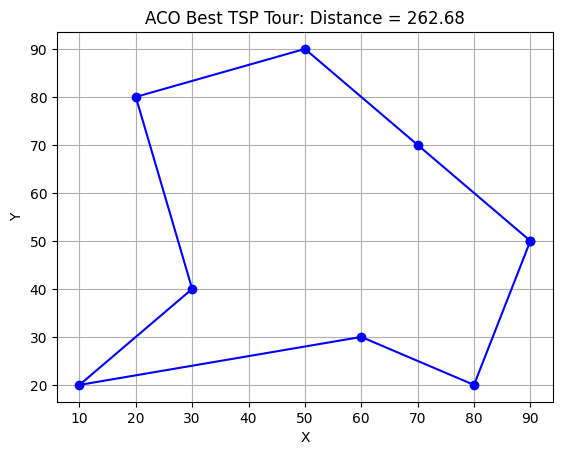

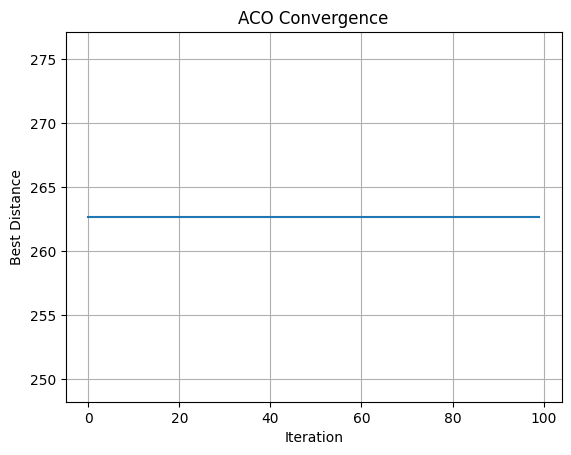

Best tour: [7, np.int64(5), np.int64(3), np.int64(1), np.int64(2), np.int64(0), np.int64(4), np.int64(6), 7]
Shortest distance: 262.68


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# City coordinates
cities = np.array([
    [10, 20], [20, 80], [30, 40], [50, 90],
    [60, 30], [70, 70], [80, 20], [90, 50]
])

n = len(cities)
dist = np.linalg.norm(cities[:, None] - cities, axis=2)
pheromone = np.ones((n, n))

ants, iterations = 20, 100
alpha, beta, rho, Q = 1, 3, 0.5, 100

best_path, best_dist = None, float("inf")
history = []

for _ in range(iterations):
    paths, lengths = [], []

    for _ in range(ants):
        path = [np.random.randint(n)]

        while len(path) < n:
            current = path[-1]
            allowed = [j for j in range(n) if j not in path]

            weight = np.array([
                pheromone[current, j]**alpha *
                (1 / (dist[current, j] + 1e-9))**beta
                for j in allowed
            ])
            prob = weight / weight.sum()
            path.append(np.random.choice(allowed, p=prob))

        length = sum(
            dist[path[i], path[(i+1) % n]] for i in range(n)
        )
        paths.append(path)
        lengths.append(length)

        if length < best_dist:
            best_path, best_dist = path.copy(), length

    pheromone *= (1 - rho)

    for path, length in zip(paths, lengths):
        for i in range(n):
            a, b = path[i], path[(i+1) % n]
            pheromone[a, b] += Q / length
            pheromone[b, a] += Q / length

    history.append(best_dist)

# Plot best tour
tour = best_path + [best_path[0]]
plt.plot(cities[tour, 0], cities[tour, 1], "b-o")
plt.title(f"ACO Best TSP Tour: Distance = {best_dist:.2f}")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid()
plt.show()

plt.plot(history)
plt.title("ACO Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Distance")
plt.grid()
plt.show()

print("Best tour:", tour)
print("Shortest distance:", round(best_dist, 2))